# 05 | Treinamento em lotes no Workbench

POC semissintética • contrato provisório • sem homologação acadêmica.
Execute em kernel reiniciado, de cima para baixo. As credenciais vêm do ambiente.


**Objetivo:** treinar no processo do Jupyter. **Entradas:** snapshot, escopo, algoritmo, lote e concorrência. `CAMPAIGN_MODE="NEW"` cria campanha e experimento novos a cada execução da célula de treino. Para retomar, escolha `RESUME` e informe a chave anterior. **Esperado:** prévia antes do fit.

In [1]:
import os, json
import pandas as pd
from IPython.display import display, Markdown
from src.workbench.application_client import call, context, save_context

from src.workbench.academic_ui import snapshot_id,metric_controls,model_table
from src.workbench.academic_data import load,prepare
SNAPSHOT_ID=snapshot_id()
CAMPAIGN_MODE=os.getenv('V4_CAMPAIGN_MODE','NEW')
RESUME_REQUEST_KEY=os.getenv('V4_RESUME_REQUEST_KEY')  # Só usado no modo RESUME.
ITEMS=[{'course_code': '2248', 'algorithm': 'ridge'}, {'course_code': '2348', 'algorithm': 'dummy'}, {'course_code': '2287', 'algorithm': 'ridge'}]
BATCH_SIZE=2
MAX_WORKERS=1
RUN_TRAINING=os.getenv('V4_RUN_TRAINING','true').lower()=='true'
frame,manifest=load(SNAPSHOT_ID)
display(pd.DataFrame([dict(**item,train_rows=len(prepare(frame,item['course_code'])[0]),evaluation_rows=len(prepare(frame,item['course_code'])[1])) for item in ITEMS]))
display({'recursos':'container Jupyter: limite3GiB; concorrência permitida1..2','targets':'regular,dependency,elective','avaliação':'holdout do último ciclo histórico; métricas sintéticas'})


,course_code,algorithm,train_rows,evaluation_rows
0,2248,ridge,50,16
1,2348,dummy,65,19
2,2287,ridge,54,23


{'recursos': 'container Jupyter: limite3GiB; concorrência permitida1..2',
 'targets': 'regular,dependency,elective',
 'avaliação': 'holdout do último ciclo histórico; métricas sintéticas'}

**Métricas:** selecione os checkboxes antes de executar a próxima célula. A seleção altera de fato o cálculo, o hash da configuração e o tracking. **Esperado:** seleção não vazia e compatível.

In [2]:

METRIC_PROFILE='forecast_extended'
metric_boxes=metric_controls(METRIC_PROFILE)


**Executar:** fit, predict, métricas, persistência proxy e Registry. **Resultado:** tabelas e links; nenhuma promoção automática.

{'modo': 'NEW',
 'request_key': 'v4-notebook-27ca1d4a-b60f-4b30-97f2-2f92d3c6c9ce',
 'retomada': 'Guarde esta chave para RESUME em caso de interrupção.'}

2026/11/05 07:24:23 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


2026/11/05 07:24:23 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: hi.demo.v4.c2248.components, version 3


{"timestamp": "2026-11-05T07:24:24.199735+00:00", "service": "workbench", "level": "INFO", "message": "model completed", "correlation_id": "83dd5205-edba-446f-90a0-cd062b4cd401", "model_key": "hi.demo.v4.c2248.components", "run_id": "5eee1810f09c40e088b1ed061d517ea1"}


2026/11/05 07:24:24 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


2026/11/05 07:24:25 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: hi.demo.v4.c2348.components, version 1


... (4 outputs left out)

[Abrir experimento 4](http://127.0.0.1:5000/#/experiments/4) · [Abrir campanha](http://127.0.0.1:5000/#/experiments/4/runs/12efbfbbd0a2497682efc838a93a539c)

,campaign_id,requested,completed,failed,quality_eligible
0,83dd5205-edba-446f-90a0-cd062b4cd401,3,3,0,3


,Curso,Modelo,Versão,Algoritmo,Qualidade,MAE_regular,RMSE_regular,Run,Registry,Manifesto,SHA256
0,2248,hi.demo.v4.c2248.components,3,ridge,VALIDATED,8.646847,10.213234,http://127.0.0.1:5000/#/experiments/4/runs/5ee...,http://127.0.0.1:5000/#/models/hi.demo.v4.c224...,s3://pucpr-poc/lineage/poc/planilha-turmas/v4/...,53d075044bf30874c87a50c856461a312271f391f61517...
1,2348,hi.demo.v4.c2348.components,1,dummy,VALIDATED,15.677778,19.338103,http://127.0.0.1:5000/#/experiments/4/runs/18e...,http://127.0.0.1:5000/#/models/hi.demo.v4.c234...,s3://pucpr-poc/lineage/poc/planilha-turmas/v4/...,df8d37f01859ac4fe1318d92772339249700e05ae0783c...
2,2287,hi.demo.v4.c2287.components,1,ridge,VALIDATED,4.969551,6.196224,http://127.0.0.1:5000/#/experiments/4/runs/b6a...,http://127.0.0.1:5000/#/models/hi.demo.v4.c228...,s3://pucpr-poc/lineage/poc/planilha-turmas/v4/...,4ce75f85c435b53342b04db8815f1c73da53b87e835ef8...


,comparison,count,models,aggregation,metrics
0,"{'task_type': 'regression', 'target_name': 're...",16,3,POOLED_OBSERVATIONS,"{'mae': {'status': 'EVALUATED', 'value': 10.36..."
1,"{'task_type': 'regression', 'target_name': 'de...",58,3,POOLED_OBSERVATIONS,"{'mae': {'status': 'EVALUATED', 'value': 1.778..."
2,"{'task_type': 'regression', 'target_name': 'el...",58,3,POOLED_OBSERVATIONS,"{'mae': {'status': 'EVALUATED', 'value': 0.695..."


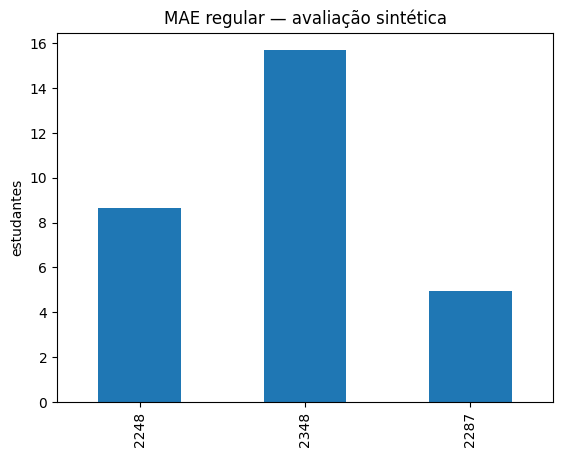

In [3]:

from src.workbench.academic_campaign import execute
from uuid import uuid4
from IPython.display import Markdown
selected=[name for name,box in metric_boxes.items() if box.value]
if not selected:
    raise ValueError('Selecione pelo menos uma métrica.')
if RUN_TRAINING:
    if CAMPAIGN_MODE not in ('NEW','RESUME'):
        raise ValueError('CAMPAIGN_MODE deve ser NEW ou RESUME.')
    if CAMPAIGN_MODE=='RESUME' and not RESUME_REQUEST_KEY:
        raise ValueError('Informe RESUME_REQUEST_KEY da campanha anterior; não será criada outra silenciosamente.')
    REQUEST_KEY='v4-notebook-'+str(uuid4()) if CAMPAIGN_MODE=='NEW' else RESUME_REQUEST_KEY
    save_context(campaign_request_key=REQUEST_KEY,campaign_id=None,proposal_id=None)
    display({'modo':CAMPAIGN_MODE,'request_key':REQUEST_KEY,'retomada':'Guarde esta chave para RESUME em caso de interrupção.'})
    result=execute(SNAPSHOT_ID,REQUEST_KEY,items=ITEMS,batch_size=BATCH_SIZE,max_workers=MAX_WORKERS,metric_profile=METRIC_PROFILE,selected_metrics=selected,resume_only=CAMPAIGN_MODE=='RESUME')
    if result['status']!='COMPLETED':
        raise RuntimeError('Campanha parcial; consulte workbench_models e eventos por campaign_id.')
    save_context(campaign_id=result['campaign_id'],snapshot_id=SNAPSHOT_ID,proposal_id=None)
    ui=os.environ['MLFLOW_UI_BASE_URL'].rstrip('/')
    display(Markdown(f"[Abrir experimento {result['experiment_id']}]({ui}/#/experiments/{result['experiment_id']}) · [Abrir campanha]({ui}/#/experiments/{result['experiment_id']}/runs/{result['run_id']})"))
    display(pd.DataFrame([{k:result[k] for k in ('campaign_id','requested','completed','failed','quality_eligible')}]))
    display(model_table(result['models']))
    display(pd.DataFrame(result['aggregation']))
    pd.Series({m['course_code']:m['metrics'].get('regular.mae') for m in result['models']}).plot.bar(title='MAE regular — avaliação sintética',ylabel='estudantes')
else:
    display('NOT_EXECUTED: treinamento desabilitado explicitamente.')


**Onde conferir:** [MLflow](http://localhost:5000), [RustFS](http://localhost:9001), [API](http://localhost:8000/docs), [Logs](http://localhost:8088). Em falha: `docker compose logs --tail 100 api inference worker mlflow`.